# 3. Batteries, the origination pipeline and the weekly report

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/energy-trading/ppa-pricing-market-analyzer/notebooks/03_bess_pipeline_and_automation.ipynb)

Battery arbitrage value by year, the value of adding storage to a solar park, a Salesforce-style pipeline report and the automated weekly market report.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "energy-trading/ppa-pricing-market-analyzer"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlsxwriter"], check=True)
else:
    here = Path.cwd()
    while not (here / "src" / "ppalab").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: ppa-pricing-market-analyzer


In [2]:
from ppalab import market as M, trends as T, pricing as P, bess as B, crm as C
d = M.load()
h = T.enrich(d["hourly"])
print(len(h), "hours from", h.timestamp.min().date(), "to", h.timestamp.max().date())

68664 hours from 2019-01-01 to 2026-10-31


In [3]:
daily = B.run(d["hourly"])
B.yearly(daily).round(0)

,year,days,revenue_eur,cycles,revenue_eur_per_mw_year,realistic_eur_per_mw_year
0,2019,365,18258.0,384.0,18258.0,13694.0
1,2020,366,14420.0,412.0,14380.0,10785.0
2,2021,365,50764.0,570.0,50764.0,38073.0
3,2022,365,145668.0,708.0,145668.0,109251.0
4,2023,365,58688.0,602.0,58688.0,44016.0
5,2024,366,32993.0,532.0,32903.0,24677.0
6,2025,365,38702.0,529.0,38702.0,29027.0
7,2026,304,39277.0,440.0,47158.0,35369.0


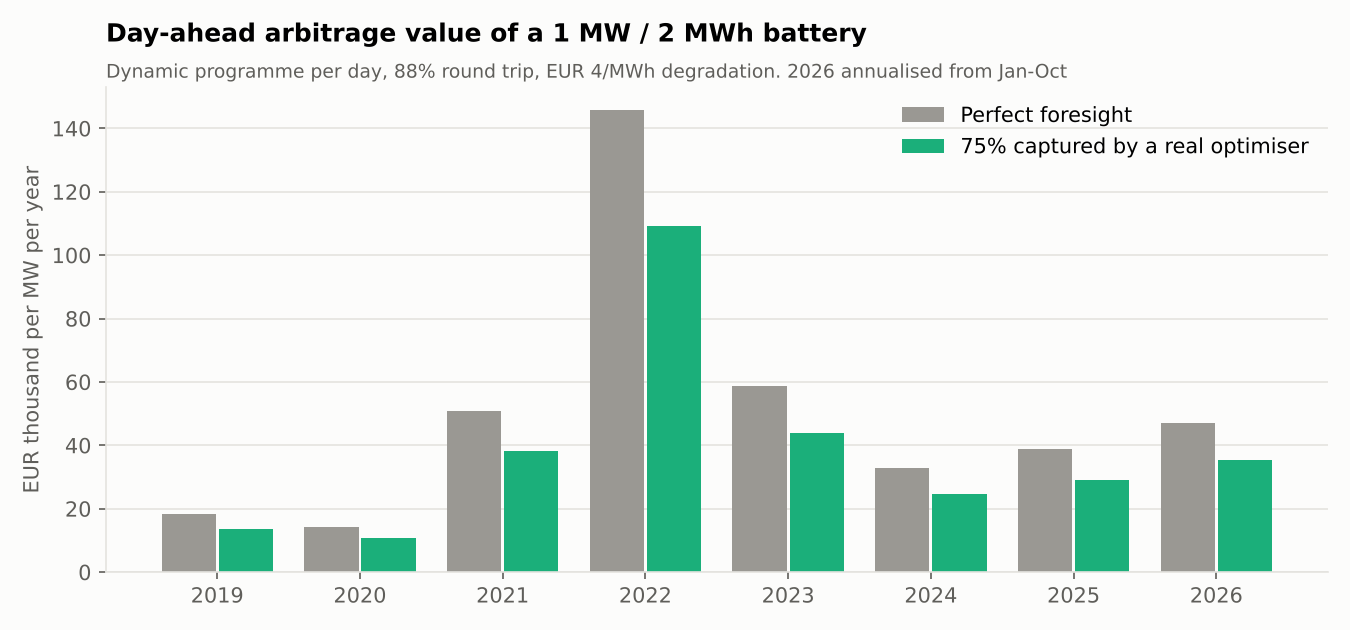

In [4]:
display(Image("outputs/figures/bess_value.png"))

In [5]:
B.solar_plus_storage(d["hourly"]).round(2)

,year,solar_capture,with_storage,uplift_eur_mwh
0,2019,39.27,43.38,4.12
1,2020,36.48,39.96,3.48
2,2021,81.31,94.20,12.90
3,2022,150.18,192.13,41.95
4,2023,85.23,103.19,17.96
5,2024,57.74,70.41,12.67
6,2025,58.20,73.22,15.02
7,2026,59.97,77.43,17.46


## Pipeline report

The checks run before any number is reported, because a forecast built on stale opportunities is wrong before it starts.

In [6]:
opp = C.load()
C.checks(opp)

,check,opportunities,examples
0,Close date missing,6,"006Q100034, 006Q100088, 006Q100091"
1,Probability does not match stage,5,"006Q100007, 006Q100028, 006Q100029"
2,Volume is zero,4,"006Q100064, 006Q100086, 006Q100130"
3,Open deal with close date in the past,52,"006Q100000, 006Q100007, 006Q100012"
4,Open deal without activity for 60+ days,43,"006Q100000, 006Q100011, 006Q100015"


In [7]:
(C.pipeline(opp) / 1e3).round(0)

Product,BESS Tolling,Baseload Swap,Solar PPA,Wind PPA
Stage,,,,
Prospecting,41.0,94.0,212.0,714.0
Qualification,235.0,215.0,530.0,2176.0
Indicative Offer,559.0,207.0,791.0,2951.0
Term Sheet,201.0,223.0,1414.0,2877.0
Negotiation,468.0,324.0,878.0,120.0


In [8]:
C.forecast(opp).round(2)

,quarter,deals,weighted_margin_eur,target_eur,coverage
0,2026Q4,19,2218976.10,2500000.0,0.89
1,2027Q1,26,6101788.25,2500000.0,2.44
2,2027Q2,15,1127523.30,2500000.0,0.45
3,2027Q3,5,691047.75,2500000.0,0.28


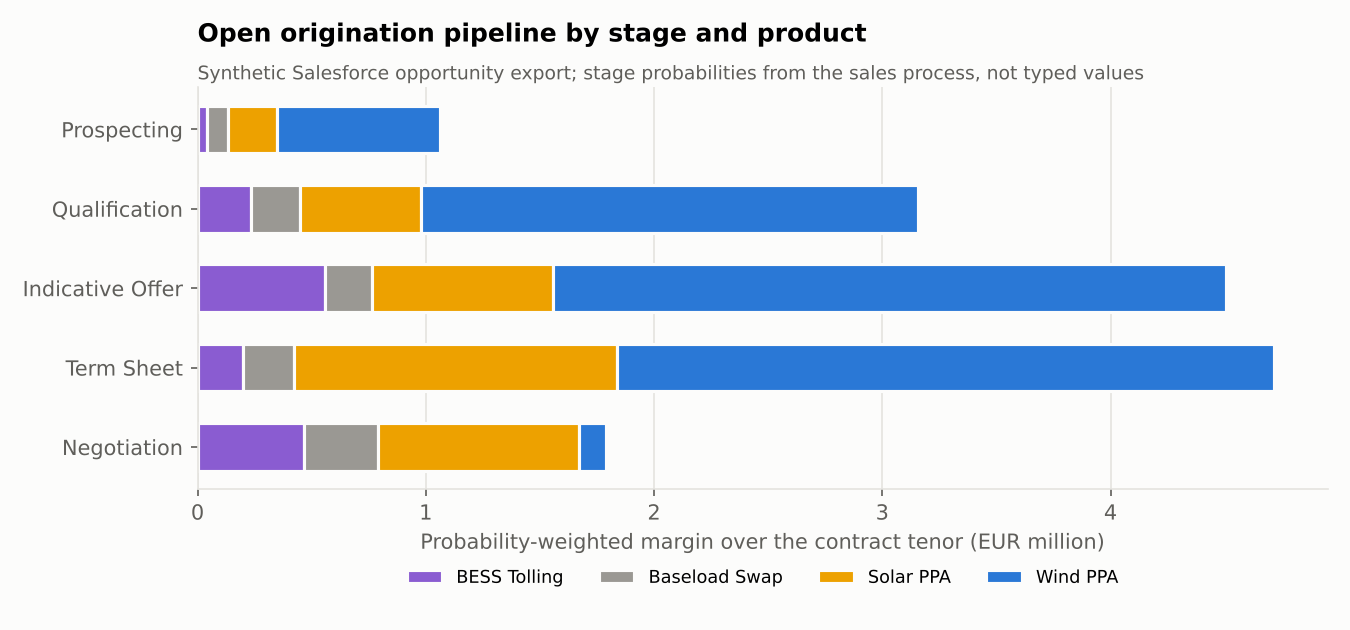

In [9]:
display(Image("outputs/figures/pipeline.png"))

## Weekly market report

`python -m ppalab.run` refreshes everything and writes this report in German:

In [10]:
print(Path("outputs/weekly_market_report_de.md").read_text())

# Wöchentlicher Marktbericht Strom DE (synthetisch), Woche bis 31.10.2026

Automatisch erzeugt mit `python -m ppalab.run`. Alle Daten sind simuliert.

## Spotmarkt

| Kennzahl | Diese Woche | Vorwoche |
|---|---|---|
| Base (€/MWh) | 101,8 | 102,4 |
| Peak (€/MWh) | 123,7 | 110,7 |
| Stunden mit negativen Preisen | 0 | 2 |
| Solar Capture Rate | 72 % | 65 % |
| Mittlerer Tagesspread (€/MWh) | 153,6 | 119,2 |

## Terminmarkt

Cal-27 Base: 72,33 €/MWh (0,05 €/MWh zur Vorwoche). Annualisierte Volatilität (60 Tage): 29 %.

## Indikative PPA-Preise (Pay-as-produced, 10 MW, 2027-2029, Gegenpartei BBB)

- Solar: 57,91 €/MWh (Capture Rate 89 %, 12 % der möglichen Erzeugung in negativen Stunden)
- Wind: 62,45 €/MWh (Capture Rate 98 %)

## Pipeline

Gewichtete Marge mit Abschluss im laufenden Quartal (2026Q4): 2,22 Mio. € bei einem Ziel von 2,50 Mio. € (89 % Abdeckung).

Datenqualität im CRM:

- Abschlussdatum fehlt: 6
- Wahrscheinlichkeit passt nicht zur Phase: 5
- Volumen ist null: 4
- Offene 